# **Taller 7: Redes Neuronales Recurrentes**

 ### **Introducción:**
Las redes neuronales recurrentes son apropiadas para resolver problemas de secuencia de datos.

En este taller resolveremos dos problemas de secuencias de números utilizando las redes neuronales recurrentes y sus variantes.

### **Los datos:**

Para este problema, se deben recrear dos conjuntos de datos, descritos a continuación:

### Conjunto 1:
Consiste de una secuencia de números de **muchos a muchos**, este conjunto está determinado por un total de 25 tuplas (X,Y):

- *X* tiene dos características o *features* (X<sub>0</sub>,X<sub>1</sub>): la primera característica inicia en un valor de 2 y continúa aumentando en 2 de tal forma que se construyan los primeros 25 números pares; la segunda característica corresponde a la suma de la primera más un valor *i* que varía de 1 a 25, siendo 1 en la primera tupla y 25 en la última.

- *Y* tiene 4 características (Y<sub>0</sub>,Y<sub>1</sub>,Y<sub>2</sub>,Y<sub>3</sub>): la primera característica corresponde al número consecutivo de la característica X<sub>0</sub>, y las siguientes tres características son los números consecutivos de X<sub>1</sub>.

A continuación se muestra un ejemplo de algunas tuplas:

| **Número de Tupla &nbsp;&nbsp;&nbsp;&nbsp;** | **X *(Input) &nbsp;*** | **Y *(Output)*** |
| --- | --- | --- |
| 1 | [2 3] | [3 4 5 6] |
| 8 | [16 24] | [17 25 26 27] |
| 15 | [30 45] | [31 46 47 48] |
| 25 | [50 75] | [51 76 77 78] |

### Conjunto 2:
Consiste de una secuencia de números de **muchos a uno**, este conjunto está determinado por un total de 25 tuplas (X,Y):

- *X* tiene dos características (X<sub>0</sub>,X<sub>1</sub>): la primera característica inicia en un valor de 3 y continúa aumentando en 2 de tal forma que se construyan los 25 números impares siguientes al 1; la segunda característica corresponde al número consecutivo de X<sub>0</sub>.

- *Y* cuenta con una única característica Y<sub>0</sub> que corresponde al número par más cercano **por debajo** a X<sub>0</sub>, es decir X<sub>0</sub>-1, de esta forma, *Y* estará formada por un vector de 25 valores que corresponde a los primeros 25 números pares iniciando en 2.

A continuación se muestra un ejemplo de algunas tuplas:

| **Número de Tupla &nbsp;&nbsp;&nbsp;&nbsp;** | **X *(Input) &nbsp;*** | **Y *(Output)*** |
| --- | --- | --- |
| 1 | [3 4] | [2] |
| 8 | [17 18] | [16] |
| 15 | [31 32] | [30] |
| 25 | [51 52] | [50] |

---
La idea principal es que los modelos de RNNs y sus variantes aprendan las secuencias de (X,Y) y luego puedan predecir los números consecutivos para cualquier nueva entrada de X.

### **Parte 1:**
Los puntos descritos a continuación deben ser resueltos utilizando el **conjunto 1**:

1. Implementar el conjunto de datos y utilizar una estrategia para redimensionar y normalizar los datos (X,Y) para que puedan ser procesador por los modelos de RNNs.

    - Tip: se recomienda utilizar [NumPy](https://numpy.org/doc/stable/) para el manejo de arreglos.


In [17]:
import numpy as np

N_SAMPLES = 25
N_FEATURES_IN = 2
N_FEATURES_OUT = 4
N_TIMESTEPS = 1

X_data, Y_data = [], []
for i in range(1, N_SAMPLES + 1):
    X0 = 2 * i
    X1 = X0 + i
    
    Y0 = X0 + 1
    Y1 = X1 + 1
    Y2 = X1 + 2
    Y3 = X1 + 3
    
    X_data.append([X0, X1])
    Y_data.append([Y0, Y1, Y2, Y3])

print("Tupla 1 (X):", X_data[0], Y_data[0])
print("Tupla 8 (X):", X_data[7], Y_data[7])
print("Tupla 15 (X):", X_data[14], Y_data[14])
print("Tupla 25 (X):", X_data[24], Y_data[24])

X= np.array(X_data)
Y= np.array(Y_data)

# Reshape para el formato RNN: [muestras, pasos_de_tiempo, características]
X_reshaped = X.reshape(N_SAMPLES, N_TIMESTEPS, N_FEATURES_IN)


Tupla 1 (X): [2, 3] [3, 4, 5, 6]
Tupla 8 (X): [16, 24] [17, 25, 26, 27]
Tupla 15 (X): [30, 45] [31, 46, 47, 48]
Tupla 25 (X): [50, 75] [51, 76, 77, 78]


2. Implementar los  de 4 modelos de redes neuronales recurrentes: una RNN básica (SimpleRNN), una LSTM, un LSTM apilado y un BiLSTM.

In [18]:
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense, Bidirectional

N_UNITS = 50

# Definición del optimizador y función de pérdida
optimizer = 'adam'
loss_fn = 'mse' 

# --- Modelo 1: RNN Básica (SimpleRNN) ---
model_rnn = Sequential([
    SimpleRNN(N_UNITS, activation='relu', input_shape=(N_TIMESTEPS, N_FEATURES_IN)), 
    Dense(N_FEATURES_OUT) 
], name="SimpleRNN_Basica")
model_rnn.compile(optimizer=optimizer, loss=loss_fn)


# --- Modelo 2: LSTM Estándar ---
# LSTM utiliza una celda de memoria para capturar dependencias a largo plazo [5].
model_lstm = Sequential([
    LSTM(N_UNITS, activation='relu', input_shape=(N_TIMESTEPS, N_FEATURES_IN)),
    Dense(N_FEATURES_OUT)
], name="LSTM_Estandar")
model_lstm.compile(optimizer=optimizer, loss=loss_fn)


# --- Modelo 3: Stacked LSTM (LSTM Apilado) ---
# Se utiliza return_sequences=True en la primera capa para pasar la salida secuencial a la siguiente capa [6].
model_stacked_lstm = Sequential([
    LSTM(N_UNITS, activation='relu', return_sequences=True, input_shape=(N_TIMESTEPS, N_FEATURES_IN)),
    LSTM(N_UNITS, activation='relu'), 
    Dense(N_FEATURES_OUT)
], name="LSTM_Apilado")
model_stacked_lstm.compile(optimizer=optimizer, loss=loss_fn)


# --- Modelo 4: BiLSTM (Bidireccional LSTM) ---
# El Bidirectional wrapper permite que la red procese la secuencia en ambas direcciones [7].
model_bilstm = Sequential([
    Bidirectional(LSTM(N_UNITS, activation='relu'), input_shape=(N_TIMESTEPS, N_FEATURES_IN)),
    Dense(N_FEATURES_OUT)
], name="BiLSTM")
model_bilstm.compile(optimizer=optimizer, loss=loss_fn)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [19]:
EPOCHS = 100 
BATCH_SIZE = 5
VALIDATION_SPLIT = 0.2 # 20% del conjunto de datos para validación [1, 2]

print("Iniciando entrenamiento...")

# RNN
history_rnn = model_rnn.fit(X_reshaped, Y, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0, validation_split=VALIDATION_SPLIT)
print(f"Modelo SimpleRNN entrenado. Pérdida final (Loss): {history_rnn.history['loss'][-1]:.4f}")

# LSTM Estándar
history_lstm = model_lstm.fit(X_reshaped, Y, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0, validation_split=VALIDATION_SPLIT)
print(f"Modelo LSTM Estándar entrenado. Pérdida final (Loss): {history_lstm.history['loss'][-1]:.4f}")

# Stacked LSTM
history_stacked_lstm = model_stacked_lstm.fit(X_reshaped, Y, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0, validation_split=VALIDATION_SPLIT)
print(f"Modelo Stacked LSTM entrenado. Pérdida final (Loss): {history_stacked_lstm.history['loss'][-1]:.4f}")

# BiLSTM
history_bilstm = model_bilstm.fit(X_reshaped, Y, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0, validation_split=VALIDATION_SPLIT)
print(f"Modelo BiLSTM entrenado. Pérdida final (Loss): {history_bilstm.history['loss'][-1]:.4f}")


model_rnn.summary()
model_lstm.summary()
model_stacked_lstm.summary()
model_bilstm.summary()

Iniciando entrenamiento...
Modelo SimpleRNN entrenado. Pérdida final (Loss): 0.5443
Modelo LSTM Estándar entrenado. Pérdida final (Loss): 2.7182
Modelo Stacked LSTM entrenado. Pérdida final (Loss): 0.2273
Modelo BiLSTM entrenado. Pérdida final (Loss): 0.7212


Model: "SimpleRNN_Basica"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_2 (SimpleRNN)        │ (None, 50)             │         2,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 4)              │           204 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,564 (33.46 KB)

 Trainable params: 2,854 (11.15 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_18                │ (None, 100)            │        21,200 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 4)              │           404 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,814 (253.18 KB)

 Trainable params: 21,604 (84.39 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 43,210 (168.79 KB)

3. Probar los 4 modelos con una **nueva entrada *X*** (un solo valor), incluir una tabla de las predicciones (opcional)

In [20]:
import pandas as pd

X_test = np.array([[2, 3]]) 

X_test_reshaped = X_test.reshape(X_test.shape[0], N_TIMESTEPS, N_FEATURES_IN)

def predict(model, X_input):
    prediction = model.predict(X_input, verbose=0)
    return prediction.flatten()

# Realizar predicciones (suponiendo que 'models' está definido)
test_output1 = predict(model_rnn, X_test_reshaped)
test_output2 = predict(model_lstm, X_test_reshaped)
test_output3 = predict(model_stacked_lstm, X_test_reshaped)
test_output4 = predict(model_bilstm, X_test_reshaped)


# Crear un diccionario con los datos
data = {
    'Modelo': ['SimpleRNN', 'LSTM', 'Stacked LSTM', 'BiLSTM'],
    'Entrada': [X_test, X_test, X_test, X_test],
    'Predicción': [test_output1, test_output2, test_output3, test_output4]
}

# Crear la tabla con pandas
df = pd.DataFrame(data)
df

,Modelo,Entrada,Predicción
0,SimpleRNN,"[[2, 3]]","[2.2629116, 3.3660283, 3.6373532, 3.7085617]"
1,LSTM,"[[2, 3]]","[1.4029547, 2.011194, 2.0092757, 2.0874653]"
2,Stacked LSTM,"[[2, 3]]","[1.8750604, 2.7930121, 3.0463812, 3.5104456]"
3,BiLSTM,"[[2, 3]]","[1.9757556, 2.6753893, 2.7671273, 2.8397148]"


4. Para el problema 1, realice  una prueba de entrenamiento  para los modelos LSTM y BLSTM  variando los hiperparámetros ```epochs```, ```validation_split``` y ```batch_size``` y variando el conjunto de entrenamiento a 100 ejemplos. Responda las siguientes preguntas:
- ¿Qué significa cambiar  el  valor de los datos de validación (```validation_split```)?
- ¿Es posible que se aproxime mejor la predicción cambiando el número de épocas ```epochs``` y aumentando el ```batch_size```?
- ¿Qué efecto tuvieron los modelos LSTM y BiLSTM  con los 100 ejemplos?

In [21]:

import matplotlib.pyplot as plt

# Parámetros básicos
N_SAMPLES = 100

# === Generar datos ===
X_data, Y_data = [], []
for i in range(1, N_SAMPLES + 1):
    X0 = 2 * i
    X1 = X0 + i
    
    Y0 = X0 + 1
    Y1 = X1 + 1
    Y2 = X1 + 2
    Y3 = X1 + 3
    
    X_data.append([X0, X1])
    Y_data.append([Y0, Y1, Y2, Y3])

X_array = np.array(X_data)
Y_array = np.array(Y_data)

# Reshape para formato RNN: [muestras, pasos_de_tiempo, características]
X_reshaped = X_array.reshape(N_SAMPLES, N_TIMESTEPS, N_FEATURES_IN)

# === Datos de entrenamiento ===
X_train = X_reshaped
Y_train = Y_array

# === Definir modelos base ===
def build_lstm_model():
    model = Sequential([
        LSTM(N_UNITS, input_shape=(N_TIMESTEPS, N_FEATURES_IN)),
        Dense(N_FEATURES_OUT)
    ])
    return model

def build_bilstm_model():
    model = Sequential([
        Bidirectional(LSTM(N_UNITS), input_shape=(N_TIMESTEPS, N_FEATURES_IN)),
        Dense(N_FEATURES_OUT)
    ])
    return model

# === Hiperparámetros a probar ===
params = [
    {'epochs': 200, 'validation_split': 0.1, 'batch_size': 8},
    {'epochs': 300, 'validation_split': 0.2, 'batch_size': 8},
    {'epochs': 400, 'validation_split': 0.2, 'batch_size': 16},
    {'epochs': 800, 'validation_split': 0.2, 'batch_size': 32},
    {'epochs': 800, 'validation_split': 0.3, 'batch_size': 32},

]

results = []

# === Entrenamiento ===
for p in params:
    # Crear modelos nuevos por cada prueba
    model_lstm = build_lstm_model()
    model_bilstm = build_bilstm_model()

    # LSTM
    model_lstm.compile(optimizer='adam', loss='mse')
    history_lstm = model_lstm.fit(
        X_train, Y_train,
        epochs=p['epochs'],
        batch_size=p['batch_size'],
        validation_split=p['validation_split'],
        verbose=0
    )
    lstm_val_loss = history_lstm.history['val_loss'][-1]

    # BiLSTM
    model_bilstm.compile(optimizer='adam', loss='mse')
    history_bilstm = model_bilstm.fit(
        X_train, Y_train,
        epochs=p['epochs'],
        batch_size=p['batch_size'],
        validation_split=p['validation_split'],
        verbose=0
    )
    bilstm_val_loss = history_bilstm.history['val_loss'][-1]

    results.append({
        'epochs': p['epochs'],
        'validation_split': p['validation_split'],
        'batch_size': p['batch_size'],
        'lstm_val_loss': lstm_val_loss,
        'bilstm_val_loss': bilstm_val_loss,
        'model_lstm': model_lstm,
        'model_bilstm': model_bilstm
    })

# === Mostrar resultados en DataFrame ===
results_df = pd.DataFrame(results)
print(results_df['epochs', 'bilstm_val_loss', 'lstm_val_loss', 'validation_split', 'batch_size'])

# === Graficar comparación de pérdidas de validación ===
plt.figure(figsize=(8, 5))
plt.plot(results_df['epochs'], results_df['lstm_val_loss'], marker='o', label='LSTM')
plt.plot(results_df['epochs'], results_df['bilstm_val_loss'], marker='s', label='BiLSTM')
plt.title('Comparación de Pérdida de Validación: LSTM vs BiLSTM')
plt.xlabel('Épocas')
plt.ylabel('Pérdida de Validación (MSE)')
plt.legend()
plt.grid(True)
plt.show()


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


KeyError: ('epochs', 'bilstm_val_loss', 'lstm_val_loss', 'validation_split', 'batch_size')

In [ ]:


X_test = np.array([2, 5]) 
X_test_reshaped = X_test.reshape(1, N_TIMESTEPS, N_FEATURES_IN)

# Realizar predicciones (suponiendo que 'models' está definido)
test_output2 = results[4]['model_lstm'].predict(X_test_reshaped, verbose=0)
test_output4 = results[4]['model_bilstm'].predict(X_test_reshaped, verbose=0)


# Crear un diccionario con los datos
data = {
    'Modelo': [ 'LSTM', 'BiLSTM'],
    'Entrada': [X_test, X_test],
    'Predicción': [ test_output2, test_output4]
}

# Crear la tabla con pandas
df = pd.DataFrame(data)
df

,Modelo,Entrada,Predicción
0,LSTM,"[2, 5]","[[4.0943546, 5.5940766, 5.654857, 6.3913274]]"
1,BiLSTM,"[2, 5]","[[3.3535283, 5.63813, 5.940257, 6.221384]]"


### **Parte 2:**
Los puntos descritos a continuación deben ser resueltos utilizando el **conjunto 2**:

5. Implementar el conjunto de datos y utilizar una estrategia para redimensionar y normalizar los datos (X,Y) para que puedan ser procesador por los modelos de RNNs.

In [ ]:

N_TIMESTEPS = 1  
N_FEATURES_IN = 2  
N_FEATURES_OUT = 1 

# 2. Generación del Conjunto de Datos (X, Y)
X_data = []
Y_data = []

for i in range(1, N_SAMPLES + 1):
    # X_0: Números impares, empezando en 3 (3, 5, 7, ..., 51)
    X0 = 2 * i + 1 
    # X_1: Consecutivo de X_0
    X1 = X0 + 1
    
    Y0 = X0 - 1
    
    X_data.append([X0, X1])
    Y_data.append([Y0])

X = np.array(X_data)
Y = np.array(Y_data)

print("Tupla 1 (X):", X_data[0], Y_data[0])
print("Tupla 8 (X):", X_data[7], Y_data[7])
print("Tupla 15 (X):", X_data[14], Y_data[14])
print("Tupla 25 (X):", X_data[24], Y_data[24])


# Reshape para el formato RNN: [muestras, pasos_de_tiempo, características]
X_reshaped = X.reshape(N_SAMPLES, N_TIMESTEPS, N_FEATURES_IN)



Tupla 1 (X): [3, 4] [2]
Tupla 8 (X): [17, 18] [16]
Tupla 15 (X): [31, 32] [30]
Tupla 25 (X): [51, 52] [50]


6. Implementar los 4 modelos de redes neuronales recurrentes: una RNN básica (SimpleRNN), una LSTM, un LSTM apilado y un BiLSTM.

In [ ]:
N_UNITS = 50

# Definición del optimizador y función de pérdida
optimizer = 'adam'
loss_fn = 'mse' 

# --- Modelo 1: RNN Básica (SimpleRNN) ---
model_rnn = Sequential([
    SimpleRNN(N_UNITS, activation='relu', input_shape=(N_TIMESTEPS, N_FEATURES_IN)), 
    Dense(N_FEATURES_OUT) 
], name="SimpleRNN_Basica")
model_rnn.compile(optimizer=optimizer, loss=loss_fn)


# --- Modelo 2: LSTM Estándar ---
# LSTM utiliza una celda de memoria para capturar dependencias a largo plazo [5].
model_lstm = Sequential([
    LSTM(N_UNITS, activation='relu', input_shape=(N_TIMESTEPS, N_FEATURES_IN)),
    Dense(N_FEATURES_OUT)
], name="LSTM_Estandar")
model_lstm.compile(optimizer=optimizer, loss=loss_fn)


# --- Modelo 3: Stacked LSTM (LSTM Apilado) ---
# Se utiliza return_sequences=True en la primera capa para pasar la salida secuencial a la siguiente capa [6].
model_stacked_lstm = Sequential([
    LSTM(N_UNITS, activation='relu', return_sequences=True, input_shape=(N_TIMESTEPS, N_FEATURES_IN)),
    LSTM(N_UNITS, activation='relu'), 
    Dense(N_FEATURES_OUT)
], name="LSTM_Apilado")
model_stacked_lstm.compile(optimizer=optimizer, loss=loss_fn)


# --- Modelo 4: BiLSTM (Bidireccional LSTM) ---
# El Bidirectional wrapper permite que la red procese la secuencia en ambas direcciones [7].
model_bilstm = Sequential([
    Bidirectional(LSTM(N_UNITS, activation='relu'), input_shape=(N_TIMESTEPS, N_FEATURES_IN)),
    Dense(N_FEATURES_OUT)
], name="BiLSTM")
model_bilstm.compile(optimizer=optimizer, loss=loss_fn)

model_rnn.summary()
model_lstm.summary()
model_stacked_lstm.summary()
model_bilstm.summary()

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "SimpleRNN_Basica"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 50)             │         2,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,701 (10.55 KB)

 Trainable params: 2,701 (10.55 KB)

...

Model: "BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_6 (Bidirectional) │ (None, 100)            │        21,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,301 (83.21 KB)

 Trainable params: 21,301 (83.21 KB)

 Non-trainable params: 0 (0.00 B)

7. Probar los 4 modelos con una **nueva entrada *X*** (un conjunto de 5 valores), incluir una tabla con las predicciones de los 4 modelos (opcional)

In [ ]:
EPOCHS = 800 
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.3 # 30% del conjunto de datos para validación

print("Iniciando entrenamiento...")

# RNN
history_rnn = model_rnn.fit(X_reshaped, Y, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0, validation_split=VALIDATION_SPLIT)
print(f"Modelo SimpleRNN entrenado. Pérdida final (Loss): {history_rnn.history['loss'][-1]:.4f}")

# LSTM Estándar
history_lstm = model_lstm.fit(X_reshaped, Y, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0, validation_split=VALIDATION_SPLIT)
print(f"Modelo LSTM Estándar entrenado. Pérdida final (Loss): {history_lstm.history['loss'][-1]:.4f}")

# Stacked LSTM
history_stacked_lstm = model_stacked_lstm.fit(X_reshaped, Y, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0, validation_split=VALIDATION_SPLIT)
print(f"Modelo Stacked LSTM entrenado. Pérdida final (Loss): {history_stacked_lstm.history['loss'][-1]:.4f}")

# BiLSTM
history_bilstm = model_bilstm.fit(X_reshaped, Y, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0, validation_split=VALIDATION_SPLIT)
print(f"Modelo BiLSTM entrenado. Pérdida final (Loss): {history_bilstm.history['loss'][-1]:.4f}")


Iniciando entrenamiento...
Modelo SimpleRNN entrenado. Pérdida final (Loss): 0.0000
Modelo LSTM Estándar entrenado. Pérdida final (Loss): 0.2846
Modelo Stacked LSTM entrenado. Pérdida final (Loss): 0.0009
Modelo BiLSTM entrenado. Pérdida final (Loss): 0.0014


In [ ]:

input = np.array([[2,3]])
X_test_reshaped = input.reshape(input.shape[0], N_TIMESTEPS, N_FEATURES_IN)

def predict(model, X_input):
    prediction = model.predict(X_input, verbose=0)
    return prediction.flatten()

test_output1 = predict(model_rnn, X_test_reshaped)
test_output2 = predict(model_lstm, X_test_reshaped)
test_output3 = predict(model_stacked_lstm, X_test_reshaped)
test_output4 = predict(model_bilstm, X_test_reshaped)

# Crear un diccionario con los datos
data = {
    'Modelo': ['SimpleRNN', 'LSTM', 'Stacked LSTM', 'BiLSTM'],
    'Entrada': [input[0], input[0], input[0], input[0]],
    'Predicción': [test_output1, test_output2, test_output3, test_output4]
}

# Crear la tabla con pandas
df = pd.DataFrame(data)
df

,Modelo,Entrada,Predicción
0,SimpleRNN,"[2, 3]",[1.0128812]
1,LSTM,"[2, 3]",[1.7486981]
2,Stacked LSTM,"[2, 3]",[1.3203275]
3,BiLSTM,"[2, 3]",[1.3021936]


8.  Para el problema 2, realice  una prueba de entrenamiento  para los modelos LSTM y BLSTM  variando los hiperparámetros ```epochs```, ```validation_split``` y ```batch_size``` y variando el conjunto de entrenamiento a 100 ejemplos. Responda las siguientes preguntas:
- ¿Qué significa cambiar  el  valor de los datos de validación (```validation_split```)?
- ¿Es posible que se aproxime mejor la predicción cambiando el número de épocas ```epochs``` y aumentando el ```batch_size```?
-  ¿Qué efecto tuvieron los modelos LSTM y BiLSTM  con los 100 ejemplos?

   epochs  validation_split  batch_size  lstm_val_loss  bilstm_val_loss  \
0     200               0.1           8   13221.684570      6997.990723   
1     300               0.2           8    9658.041992      3762.441895   
2     400               0.2          16   13817.403320      7203.612305   
3     800               0.2          32   10782.345703      5187.752930   
4     800               0.3          32   10387.092773      5019.957520   

                                  model_bilstm  \
0  <Sequential name=sequential_23, built=True>   
1  <Sequential name=sequential_25, built=True>   
2  <Sequential name=sequential_27, built=True>   
3  <Sequential name=sequential_29, built=True>   
4  <Sequential name=sequential_31, built=True>   

                                    model_lstm  
0  <Sequential name=sequential_22, built=True>  
1  <Sequential name=sequential_24, built=True>  
2  <Sequential name=sequential_26, built=True>  
3  <Sequential name=sequential_28, built=True>  
4  

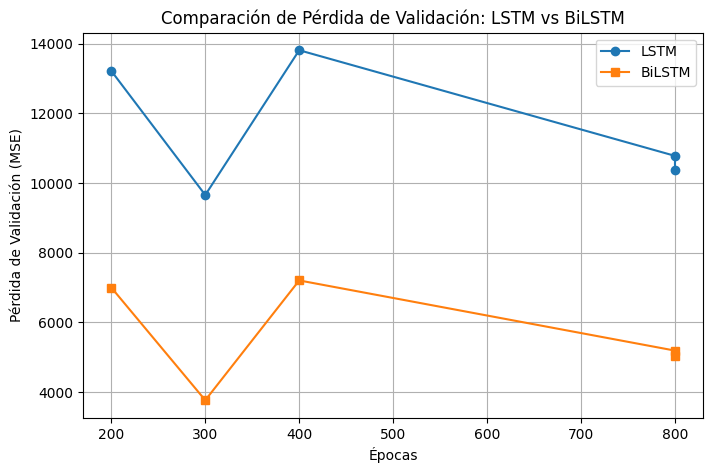

In [ ]:

import matplotlib.pyplot as plt

# Parámetros básicos
N_SAMPLES = 100

# === Generar datos ===
X_data, Y_data = [], []
for i in range(1, N_SAMPLES + 1):
    X0 = 2 * i + 1 
    X1 = X0 + 1
    
    Y0 = X0 - 1
    
    X_data.append([X0, X1])
    Y_data.append([Y0])

X_array = np.array(X_data)
Y_array = np.array(Y_data)

# Reshape para formato RNN: [muestras, pasos_de_tiempo, características]
X_reshaped = X_array.reshape(N_SAMPLES, N_TIMESTEPS, N_FEATURES_IN)

# === Datos de entrenamiento ===
X_train = X_reshaped
Y_train = Y_array

# === Definir modelos base ===
def build_lstm_model():
    model = Sequential([
        LSTM(N_UNITS, input_shape=(N_TIMESTEPS, N_FEATURES_IN)),
        Dense(N_FEATURES_OUT)
    ])
    return model

def build_bilstm_model():
    model = Sequential([
        Bidirectional(LSTM(N_UNITS), input_shape=(N_TIMESTEPS, N_FEATURES_IN)),
        Dense(N_FEATURES_OUT)
    ])
    return model

# === Hiperparámetros a probar ===
params = [
    {'epochs': 200, 'validation_split': 0.1, 'batch_size': 8},
    {'epochs': 300, 'validation_split': 0.2, 'batch_size': 8},
    {'epochs': 400, 'validation_split': 0.2, 'batch_size': 16},
    {'epochs': 800, 'validation_split': 0.2, 'batch_size': 32},
    {'epochs': 800, 'validation_split': 0.3, 'batch_size': 32},
]

results = []

# === Entrenamiento ===
for p in params:
    # Crear modelos nuevos por cada prueba
    model_lstm = build_lstm_model()
    model_bilstm = build_bilstm_model()

    # LSTM
    model_lstm.compile(optimizer='adam', loss='mse')
    history_lstm = model_lstm.fit(
        X_train, Y_train,
        epochs=p['epochs'],
        batch_size=p['batch_size'],
        validation_split=p['validation_split'],
        verbose=0
    )
    lstm_val_loss = history_lstm.history['val_loss'][-1]

    # BiLSTM
    model_bilstm.compile(optimizer='adam', loss='mse')
    history_bilstm = model_bilstm.fit(
        X_train, Y_train,
        epochs=p['epochs'],
        batch_size=p['batch_size'],
        validation_split=p['validation_split'],
        verbose=0
    )
    bilstm_val_loss = history_bilstm.history['val_loss'][-1]

    results.append({
        'epochs': p['epochs'],
        'validation_split': p['validation_split'],
        'batch_size': p['batch_size'],
        'lstm_val_loss': lstm_val_loss,
        'bilstm_val_loss': bilstm_val_loss,
        'model_bilstm': model_bilstm,
        'model_lstm': model_lstm

    })

# === Mostrar resultados en DataFrame ===
results_df = pd.DataFrame(results)
print(results_df['epochs', 'validation_split', 'batch_size', 'lstm_val_loss', 'bilstm_val_loss'])

# === Graficar comparación de pérdidas de validación ===
plt.figure(figsize=(8, 5))
plt.plot(results_df['epochs'], results_df['lstm_val_loss'], marker='o', label='LSTM')
plt.plot(results_df['epochs'], results_df['bilstm_val_loss'], marker='s', label='BiLSTM')
plt.title('Comparación de Pérdida de Validación: LSTM vs BiLSTM')
plt.xlabel('Épocas')
plt.ylabel('Pérdida de Validación (MSE)')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
X_test = np.array([2, 5]) 
X_test_reshaped = X_test.reshape(1, N_TIMESTEPS, N_FEATURES_IN)

# Realizar predicciones (suponiendo que 'models' está definido)
test_output2 = results[1]['model_lstm'].predict(X_test_reshaped, verbose=0)
test_output4 = results[1]['model_bilstm'].predict(X_test_reshaped, verbose=0)


# Crear un diccionario con los datos
data = {
    'Modelo': [ 'LSTM', 'BiLSTM'],
    'Entrada': [X_test, X_test],
    'Predicción': [ test_output2, test_output4]
}

# Crear la tabla con pandas
df = pd.DataFrame(data)
df

,Modelo,Entrada,Predicción
0,LSTM,"[2, 5]",[[4.3271265]]
1,BiLSTM,"[2, 5]",[[4.3043685]]
